> **Trainierte Modelle:** Dieses Notebook lädt das fertige Modell aus `models/` und trainiert nicht neu. Zum Neutrainieren in den Parametern `TRAIN_MODEL = True` setzen.

# 👖 Autoencoders on Fashion MNIST

## Source notes

#### Sources adapated from:

Notebook adapated for Google Colab from the codebase (https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition) for the book:

**Generative Deep Learning**, 2nd Edition
by *David Foster*
Released April 2023
Publisher(s): O'Reilly Media, Inc.
ISBN: 9781098134181

cf: https://www.oreilly.com/library/view/generative-deep-learning/9781098134174/


#### Copyright notice:

https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition#Apache-2.0-1-ov-file

### Preparation


In [1]:
import matplotlib.pyplot as plt


def sample_batch(dataset):
    batch = dataset.take(1).get_single_element()
    if isinstance(batch, tuple):
        batch = batch[0]
    return batch.numpy()


def display(
    images, n=10, size=(20, 3), cmap="gray_r", as_type="float32", save_to=None
):
    """
    Displays n random images from each one of the supplied arrays.
    """
    if images.max() > 1.0:
        images = images / 255.0
    elif images.min() < 0.0:
        images = (images + 1.0) / 2.0

    plt.figure(figsize=size)
    for i in range(n):
        _ = plt.subplot(1, n, i + 1)
        plt.imshow(images[i].astype(as_type), cmap=cmap)
        plt.axis("off")

    if save_to:
        plt.savefig(save_to)
        print(f"\nSaved to {save_to}")

    plt.show()



In this notebook, we'll walk through the steps required to train your own autoencoder on the fashion MNIST dataset.

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models, datasets, callbacks
import tensorflow.keras.backend as K



I0000 00:00:1793543045.936410 2013775 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793543047.018837 2013775 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 0. Parameters <a name="parameters"></a>

In [3]:
IMAGE_SIZE = 32
CHANNELS = 1
BATCH_SIZE = 100
BUFFER_SIZE = 1000
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 2
EPOCHS = 3

# Eigene Modelle laden statt neu trainieren. True trainiert neu.
TRAIN_MODEL = False

## 1. Prepare the data <a name="prepare"></a>

In [4]:
# Load the data
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()

In [5]:
# Preprocess the data


def preprocess(imgs):
    """
    Normalize and reshape the images
    """
    imgs = imgs.astype("float32") / 255.0
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=0.0)
    imgs = np.expand_dims(imgs, -1)
    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

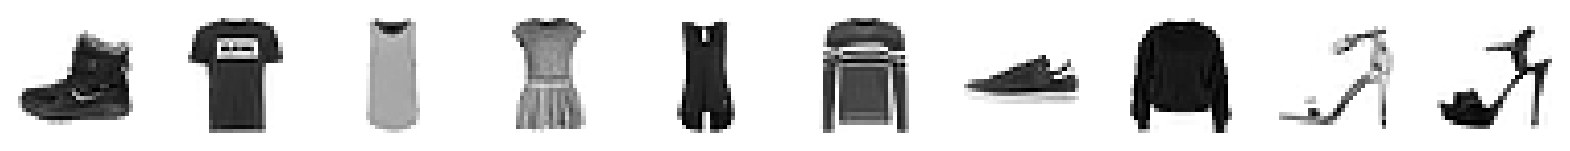

In [6]:
# Show some items of clothing from the training set
display(x_train)

## 2. Build the autoencoder <a name="build"></a>

The encoder turns a 32×32×1 image into a 2D point (`EMBEDDING_DIM = 2`) using three strided `Conv2D` layers, each halving the spatial resolution while doubling the channel count:

![Encoder architecture](images/architecture_encoder.png)

Every `Conv2D` below uses a 3×3 kernel, `strides=2` and `padding="same"`. Because stride (2) is smaller than the kernel size (3), consecutive 3×3 windows overlap by one row/column; because the input size (32) isn't evenly covered by stride-2 windows, `'same'` padding adds exactly one row and one column of zeros — only at the bottom/right edge. This was verified directly on the installed TensorFlow/Keras layer with an impulse-response test (not assumed from general convolution-arithmetic references), shown here for the first encoder layer (32×32×1 → 16×16×32):

![Conv2D mechanics](images/conv2d_mechanics.png)

In [7]:
# Encoder
encoder_input = layers.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input"
)
x = layers.Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(
    encoder_input
)
x = layers.Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(128, (3, 3), strides=2, activation="relu", padding="same")(x)
shape_before_flattening = K.int_shape(x)[1:]  # the decoder will need this!

x = layers.Flatten()(x)
encoder_output = layers.Dense(EMBEDDING_DIM, name="encoder_output")(x)

encoder = models.Model(encoder_input, encoder_output)
encoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 2)              │         4,098 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 96,770 (378.01 KB)

 Trainable params: 96,770 (378.01 KB)

 Non-trainable params: 0 (0.00 B)

The decoder mirrors the encoder with `Conv2DTranspose` layers that upsample back to 32×32×1. Shapes below are taken directly from `decoder.summary()`:

![Decoder architecture](images/architecture_decoder.png)

Each `Conv2DTranspose` uses a 3×3 kernel, `strides=2` and `padding="same"`, so every input pixel `(i, j)` is spread onto output rows/cols `[2i, 2i+3) × [2j, 2j+3)` (clipped at the border). The final `decoder_output` layer is a plain `Conv2D` with `strides=1` (no upsampling) that just maps 32 channels down to 1, using a sigmoid activation. Verified the same way, by impulse-response testing the installed `Conv2DTranspose` layer directly, for the first decoder layer (4×4×128 → 8×8×128):

![Conv2DTranspose mechanics](images/conv2dtranspose_mechanics.png)


In [8]:
# Decoder
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape_before_flattening)))(decoder_input)
x = layers.Reshape(shape_before_flattening)(x)
x = layers.Conv2DTranspose(
    128, (3, 3), strides=2, activation="relu", padding="same"
)(x)
x = layers.Conv2DTranspose(
    64, (3, 3), strides=2, activation="relu", padding="same"
)(x)
x = layers.Conv2DTranspose(
    32, (3, 3), strides=2, activation="relu", padding="same"
)(x)
decoder_output = layers.Conv2D(
    CHANNELS,
    (3, 3),
    strides=1,
    activation="sigmoid",
    padding="same",
    name="decoder_output",
)(x)

decoder = models.Model(decoder_input, decoder_output)
decoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 32, 32, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 246,273 (962.00 KB)

 Trainable params: 246,273 (962.00 KB)

 Non-trainable params: 0 (0.00 B)

### Why the decoder isn't a mirror image of the encoder

Spatial resolution mirrors exactly (32↔4 in 3 steps either way), but channel depth doesn't — the decoder needs a 4th, extra layer that has no counterpart in the encoder:

| Stage | Encoder layer | channels | spatial | Decoder layer | channels | spatial | Note |
|---|---|---|---|---|---|---|---|
| 1 | `conv2d` | 1 → 32 | 32 → 16 | `conv2d_transpose` | 128 → **128** | 4 → 8 | Encoder changes channels *and* size together; decoder's first step only changes size — channels stay at 128 |
| 2 | `conv2d_1` | 32 → 64 | 16 → 8 | `conv2d_transpose_1` | 128 → 64 | 8 → 16 | both change channels *and* size together |
| 3 | `conv2d_2` | 64 → 128 | 8 → 4 | `conv2d_transpose_2` | 64 → 32 | 16 → 32 | both change channels *and* size together |
| 4 | *(none)* | — | — | `decoder_output` (`Conv2D`, `strides=1`) | 32 → **1** | 32 → 32 (unchanged) | **extra layer, no encoder counterpart** — dedicated, non-resizing layer (`strides=1`, `padding="same"`) that only collapses the remaining 32 feature channels down to the 1 real (grayscale) channel, with sigmoid squashing the result into [0, 1] |

The root cause is stage 1: because the decoder's first `Conv2DTranspose` spends its whole budget on upsampling (4→8) and leaves channels untouched (128→128), channel reduction is pushed one layer "to the right" relative to the encoder. By the time spatial size reaches 32×32 there are still 32 feature channels left over — stage 4 exists purely to remove them. The encoder never needs an equivalent step because it starts directly at the real 1-channel input, so channel expansion and downsampling are always combined from its very first layer.

Both diagrams and padding mechanics above were verified against this exact code (`encoder.summary()` / `decoder.summary()` and impulse-response probing of the installed TensorFlow layers), not inferred from generic references.

In [9]:
# Autoencoder
autoencoder = models.Model(
    encoder_input, decoder(encoder_output)
)  # decoder(encoder_output)
autoencoder.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 2)              │         4,098 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_1 (Functional)       │ (None, 32, 32, 1)      │       246,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 343,043 (1.31 MB)

 Trainable params: 343,043 (1.31 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Train the autoencoder <a name="train"></a>

In [10]:
# Compile the autoencoder
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

In [11]:
# Create a model save checkpoint
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint.keras",
    save_weights_only=False,
    save_freq="epoch",
    monitor="loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")

In [12]:
if TRAIN_MODEL:
    autoencoder.fit(
        x_train,
        x_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        validation_data=(x_test, x_test),
        callbacks=[model_checkpoint_callback, tensorboard_callback],
    )
else:
    autoencoder.set_weights(models.load_model("./models/autoencoder_course.keras", compile=False).get_weights())

In [13]:
if TRAIN_MODEL:
    # Save the final models
    from pathlib import Path
    Path("./models").mkdir(parents=True, exist_ok=True)
    autoencoder.save("./models/autoencoder_course.keras")
    encoder.save("./models/encoder_course.keras")
    decoder.save("./models/decoder_course.keras")

## 4. Reconstruct using the autoencoder <a name="reconstruct"></a>

In [14]:
n_to_predict = 5000
example_images = x_test[:n_to_predict]
example_labels = y_test[:n_to_predict]

  1/157 ━━━━━━━━━━━━━━━━━━━━ 17s 113ms/step

 11/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step   

 21/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 30/157 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

 39/157 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

 48/157 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

... (12 outputs left out)

153/157 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


Example real clothing items


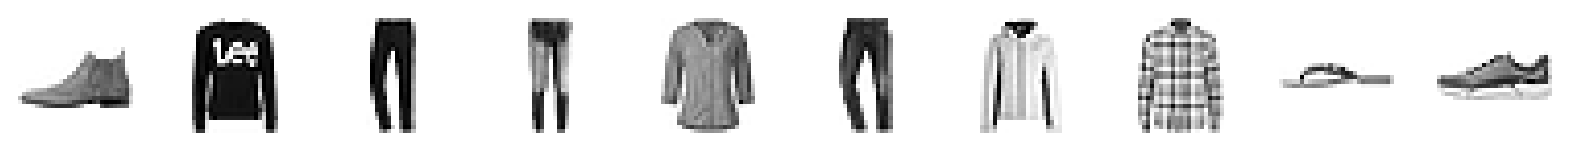

Reconstructions


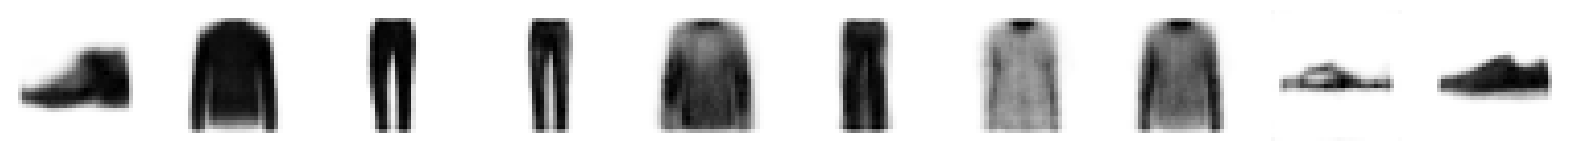

In [15]:
predictions = autoencoder.predict(example_images)

print("Example real clothing items")
display(example_images)
print("Reconstructions")
display(predictions)

## 5. Embed using the encoder <a name="encode"></a>

In [16]:
# Encode the example images
embeddings = encoder.predict(example_images)

  1/157 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step

 39/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

 78/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

117/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

154/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [17]:
# Some examples of the embeddings
print(embeddings[:10])

[[ 2.940333   -1.1950243 ]
 [-1.1950283  -8.334331  ]
 [-7.625043   -0.8109127 ]
 [-4.7789693  -0.28681314]
 [ 0.17106462 -4.5867643 ]
 [-5.1230655  -1.9314896 ]
 [-0.87919044 -2.4240997 ]
 [-0.5843628  -3.9266574 ]
 [ 2.521179    1.5309741 ]
 [ 4.4969716   0.5657285 ]]


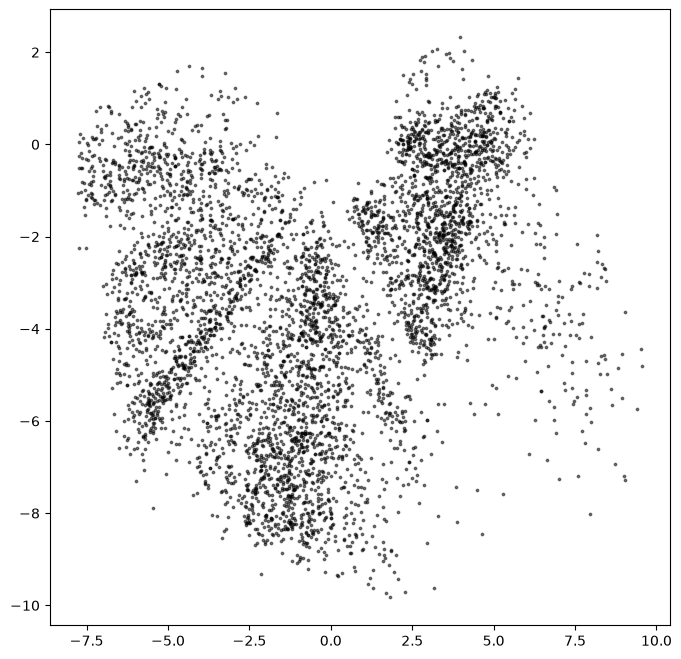

In [18]:
# Show the encoded points in 2D space
figsize = 8

plt.figure(figsize=(figsize, figsize))
plt.scatter(embeddings[:, 0], embeddings[:, 1], c="black", alpha=0.5, s=3)
plt.show()

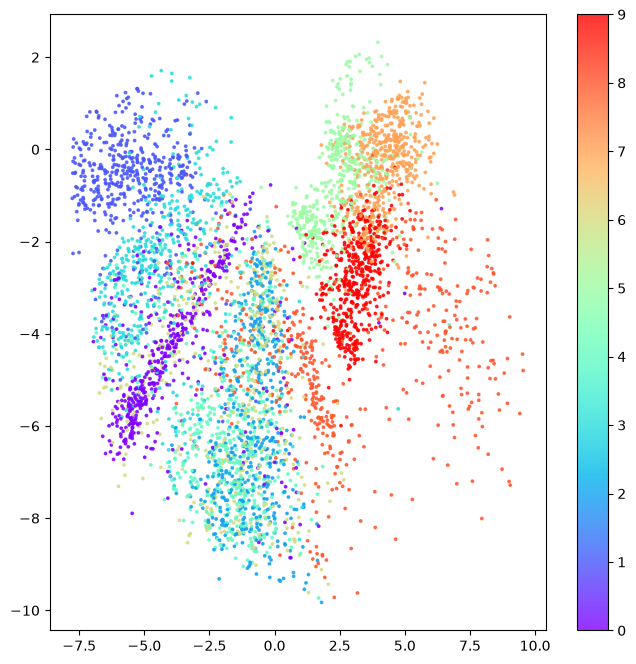

In [19]:
# Colour the embeddings by their label (clothing type - see table)
example_labels = y_test[:n_to_predict]

figsize = 8
plt.figure(figsize=(figsize, figsize))
plt.scatter(
    embeddings[:, 0],
    embeddings[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar()
plt.show()

## 6. Generate using the decoder <a name="decode"></a>

In [20]:
# Get the range of the existing embeddings
mins, maxs = np.min(embeddings, axis=0), np.max(embeddings, axis=0)

# Sample some points in the latent space
grid_width, grid_height = (6, 3)
sample = np.random.uniform(
    mins, maxs, size=(grid_width * grid_height, EMBEDDING_DIM)
)

In [21]:
# Decode the sampled points
reconstructions = decoder.predict(sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


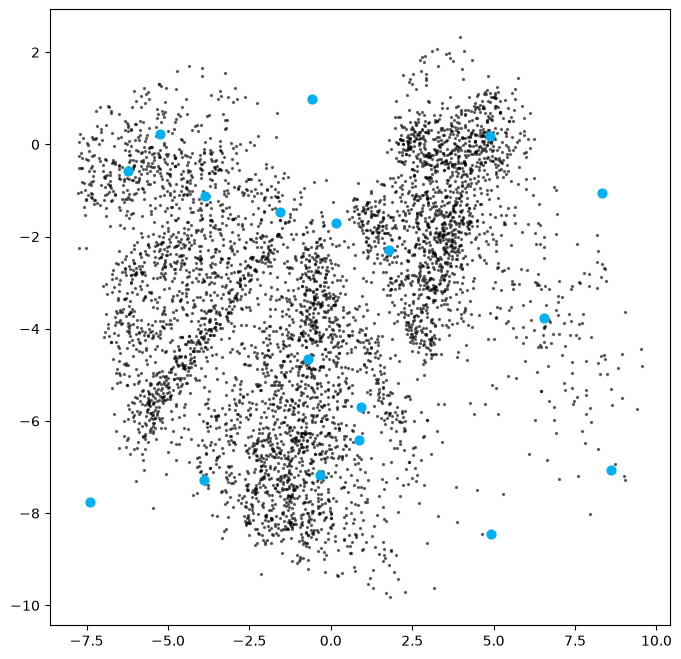

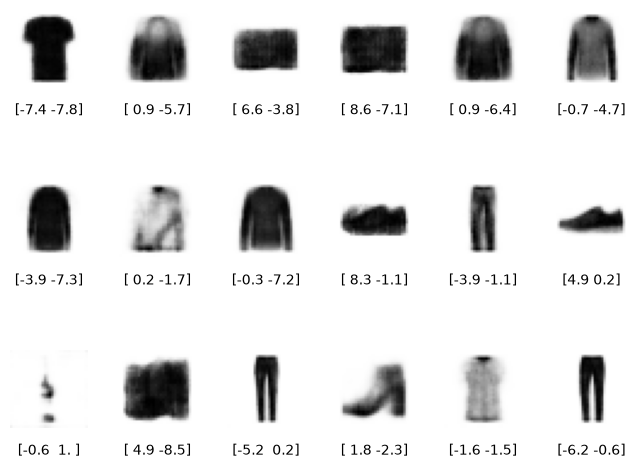

In [22]:
# Draw a plot of...
figsize = 8
plt.figure(figsize=(figsize, figsize))

# ... the original embeddings ...
plt.scatter(embeddings[:, 0], embeddings[:, 1], c="black", alpha=0.5, s=2)

# ... and the newly generated points in the latent space
plt.scatter(sample[:, 0], sample[:, 1], c="#00B0F0", alpha=1, s=40)
plt.show()

# Add underneath a grid of the decoded images
fig = plt.figure(figsize=(figsize, grid_height * 2))
fig.subplots_adjust(hspace=0.4, wspace=0.4)

for i in range(grid_width * grid_height):
    ax = fig.add_subplot(grid_height, grid_width, i + 1)
    ax.axis("off")
    ax.text(
        0.5,
        -0.35,
        str(np.round(sample[i, :], 1)),
        fontsize=10,
        ha="center",
        transform=ax.transAxes,
    )
    ax.imshow(reconstructions[i, :, :], cmap="Greys")

1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


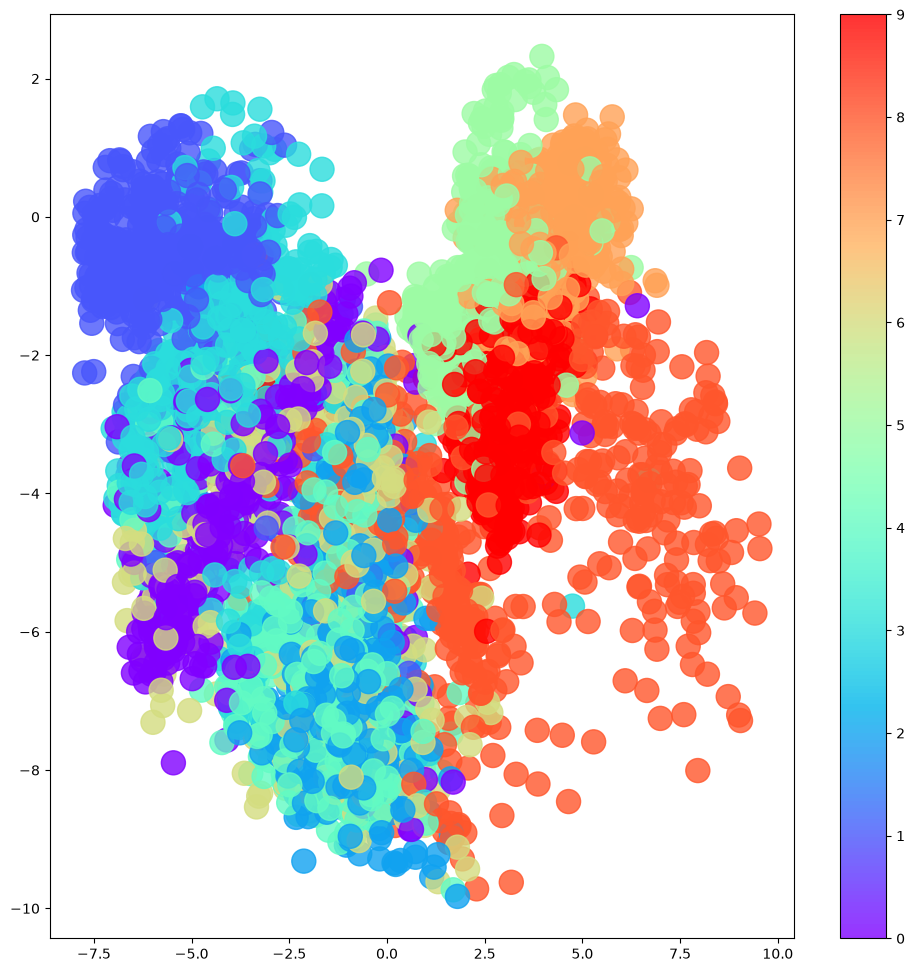

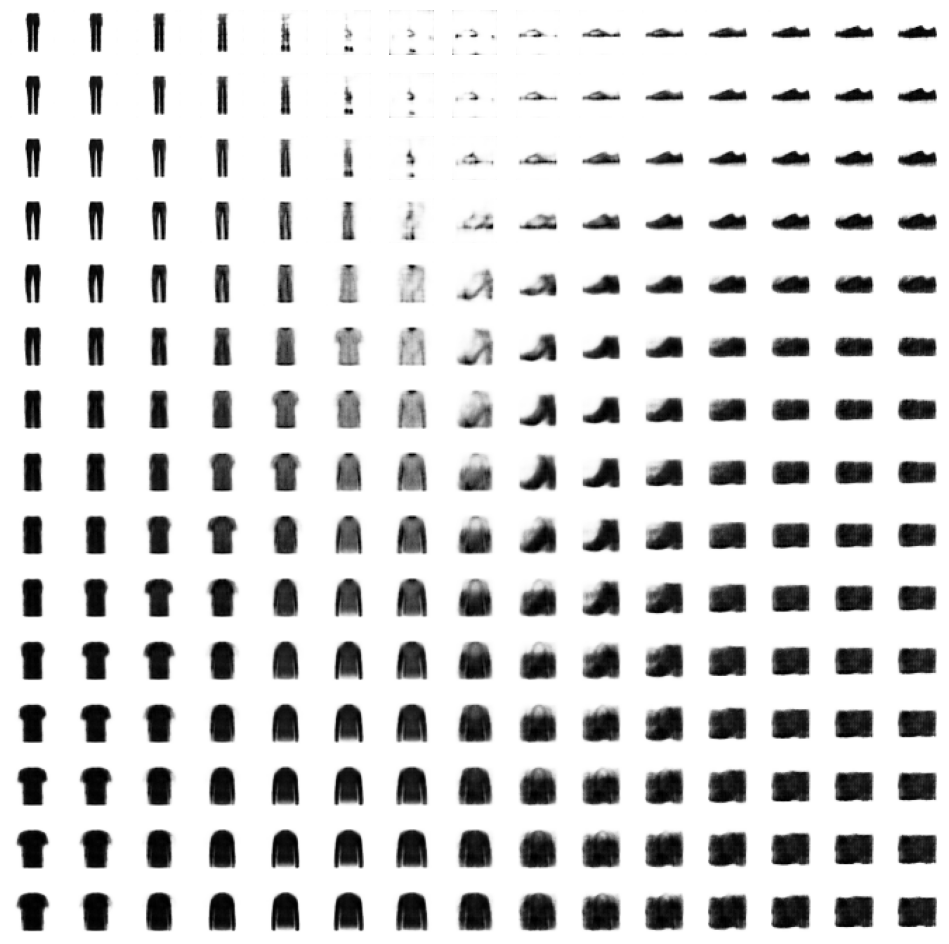

In [23]:
# Colour the embeddings by their label (clothing type - see table)
figsize = 12
grid_size = 15
plt.figure(figsize=(figsize, figsize))
plt.scatter(
    embeddings[:, 0],
    embeddings[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=300,
)
plt.colorbar()

x = np.linspace(min(embeddings[:, 0]), max(embeddings[:, 0]), grid_size)
y = np.linspace(max(embeddings[:, 1]), min(embeddings[:, 1]), grid_size)
xv, yv = np.meshgrid(x, y)
xv = xv.flatten()
yv = yv.flatten()
grid = np.array(list(zip(xv, yv)))

reconstructions = decoder.predict(grid)
# plt.scatter(grid[:, 0], grid[:, 1], c="black", alpha=1, s=10)
plt.show()

fig = plt.figure(figsize=(figsize, figsize))
fig.subplots_adjust(hspace=0.4, wspace=0.4)
for i in range(grid_size**2):
    ax = fig.add_subplot(grid_size, grid_size, i + 1)
    ax.axis("off")
    ax.imshow(reconstructions[i, :, :], cmap="Greys")

| ID | Clothing Label |
| :- | :- |
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |